# Lab 8: Support Vector Machines (SVM), Kernel Methods & Multi-Model Comparison
## Non-Linear Classification, Feature Scaling Dynamics, and Empirical Benchmarking Against Decision Trees and KNN

**Course:** M.Tech Machine Learning Laboratory  
**Topic:** Maximum-Margin Classification, Kernel Trick (Linear, RBF, Polynomial, Sigmoid), Feature Scaling Sensitivity, and Comparative Classification Diagnostics  
**Target Notebook:** `lab_8/main.ipynb`  

---

### Objectives
1. Understand the mathematical formulations of the **Support Vector Machine (SVM)** and the maximum-margin hyperplane principle.
2. Select a suitable dataset from the `datasets/` repository: **Spotify Audio Features** (binary classification: `Rock` vs. `EDM`).
3. Explore the critical impact of **feature scaling** (Raw vs. Min-Max Scaling vs. Standard Z-Score Standardization) on SVM convergence and accuracy.
4. Investigate non-linearly separable classification by implementing multiple **kernel functions**:
   - **Linear Kernel:** $K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$
   - **Radial Basis Function (RBF / Gaussian):** $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$
   - **Polynomial Kernel:** $K(\mathbf{x}, \mathbf{x}') = (\gamma \mathbf{x}^T \mathbf{x}' + r)^d$
   - **Sigmoid Kernel:** $K(\mathbf{x}, \mathbf{x}') = \tanh(\gamma \mathbf{x}^T \mathbf{x}' + r)$
5. Benchmark SVM directly against canonical machine learning classifiers: **Decision Trees** and **$K$-Nearest Neighbors (KNN)**.
6. Evaluate model effectiveness in terms of **Precision, Recall, Accuracy, and F1-Score**.
7. Plot **comparative bar graphs** and multi-panel **confusion matrix heatmaps**.


---

## 1. Theoretical Foundations of Support Vector Machines

### The Maximum-Margin Principle
Given a training dataset $\{(\mathbf{x}_i, y_i)\}_{i=1}^N$ with $\mathbf{x}_i \in \mathbb{R}^d$ and labels $y_i \in \{-1, +1\}$, the Support Vector Machine searches for the optimal separating hyperplane:
$$\mathbf{w}^T \mathbf{x} + b = 0$$
that maximizes the geometric margin $\frac{2}{\|\mathbf{w}\|}$ between the two classes.

#### Soft-Margin Optimization (Primal Formulation):
To accommodate non-separable data with overlapping class distributions, slack variables $\xi_i \ge 0$ are introduced with regularization penalty $C > 0$:
$$\min_{\mathbf{w}, b, \mathbf{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^N \xi_i \quad \text{subject to} \quad y_i (\mathbf{w}^T \phi(\mathbf{x}_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$
* High $C$: Strict penalty on misclassification (lower bias, higher risk of overfitting).
* Low $C$: Wider margin with more tolerated violations (higher bias, more robust to noise).

#### The Dual Formulation & The Kernel Trick:
Using Lagrange multipliers $\alpha_i \ge 0$, the optimization reduces to:
$$\max_{\mathbf{\alpha}} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j K(\mathbf{x}_i, \mathbf{x}_j) \quad \text{subject to} \quad 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

The **Kernel Function** $K(\mathbf{x}_i, \mathbf{x}_j) = \langle \phi(\mathbf{x}_i), \phi(\mathbf{x}_j) \rangle$ implicitly computes inner products in an infinite- or high-dimensional Hilbert feature space without explicitly calculating coordinates $\phi(\mathbf{x})$:
1. **Linear:** $K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$
2. **Radial Basis Function (RBF):** $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$
3. **Polynomial:** $K(\mathbf{x}, \mathbf{x}') = (\gamma \mathbf{x}^T \mathbf{x}' + r)^d$
4. **Sigmoid:** $K(\mathbf{x}, \mathbf{x}') = \tanh(\gamma \mathbf{x}^T \mathbf{x}' + r)$


In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from IPython.display import display

# Plot styling configuration
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.8,
    'grid.alpha': 0.5,
    'grid.linestyle': '--'
})
%matplotlib inline

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


---

## 2. Dataset Ingestion, Target Selection & Exploratory Profiling

We utilize the **Spotify Audio Features dataset** from the `datasets/` repository.
* **Target Classes:** Binary genre classification:
  - `Rock` (Class 0): Organic instrumentals, guitar distortion, moderate dynamic range.
  - `EDM` (Class 1): Electronic dance music, high compression, synthetic basslines, repetitive rhythmic drive.
* **Continuous Audio Features ($d=7$):**
  `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `valence`, `tempo`.
* **Sampling Strategy:** A balanced subset of $N=2,000$ tracks ($1,000$ Rock, $1,000$ EDM) is extracted for rapid, statistically sound experimentation.


In [2]:
# Locate and load Spotify dataset
data_path = "datasets/spotify.csv" if os.path.exists("datasets/spotify.csv") else "../datasets/spotify.csv"
df_raw = pd.read_csv(data_path)

print(f"Total tracks in corpus: {len(df_raw):,}")
print(f"Available attributes:   {df_raw.shape[1]}")

# Filter for two target genre classes
target_genres = ['rock', 'edm']
df_filtered = df_raw[df_raw['playlist_genre'].isin(target_genres)].copy()

# Sample balanced 2,000 tracks
rock_subset = df_filtered[df_filtered['playlist_genre'] == 'rock'].sample(n=1000, random_state=RANDOM_SEED)
edm_subset  = df_filtered[df_filtered['playlist_genre'] == 'edm'].sample(n=1000, random_state=RANDOM_SEED)
data = pd.concat([rock_subset, edm_subset]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

# Define feature attributes and target vector
features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence', 'tempo']
X = data[features].values
y = np.where(data['playlist_genre'] == 'edm', 1, 0) # 1: EDM, 0: Rock
target_names = ['Rock (0)', 'EDM (1)']

print(f"Experimental Subset: {len(data)} tracks ({np.sum(y == 0)} Rock, {np.sum(y == 1)} EDM)")
data[['track_name', 'track_artist', 'playlist_genre'] + features].head()


Total tracks in corpus: 32,833
Available attributes:   23
Experimental Subset: 2000 tracks (1000 Rock, 1000 EDM)


,track_name,track_artist,playlist_genre,danceability,energy,loudness,speechiness,acousticness,valence,tempo
0,Miami 82 - Vocal Radio Mix,Syn Cole,edm,0.592,0.874,-2.061,0.1550,0.06750,0.678,127.998
1,18/5/15,Nathan Aeli,rock,0.396,0.739,-6.570,0.0435,0.00001,0.338,119.949
2,Better in Time,Leona Lewis,edm,0.584,0.700,-4.251,0.0506,0.51200,0.549,163.953
3,Awa adounia,Liya Ag Ablil,rock,0.617,0.827,-8.936,0.0348,0.12500,0.846,101.154
4,Clarity - Tiësto Remix,Zedd,edm,0.591,0.924,-4.724,0.0465,0.00231,0.274,128.174


---

## 3. Stratified Train/Test Splitting

We partition the balanced dataset into **75% training** ($1,500$ tracks) and **25% testing** ($500$ tracks) using stratified sampling to preserve identical class balance across both partitions.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_SEED, stratify=y
)

print(f"Training Partition: {X_train.shape[0]} samples across {X_train.shape[1]} features")
print(f"Testing Partition:  {X_test.shape[0]} samples across {X_test.shape[1]} features")

# Descriptive feature ranges illustrating disparate scales
feature_summary = pd.DataFrame({
    'Feature': features,
    'Min': X_train.min(axis=0),
    'Mean': X_train.mean(axis=0),
    'Max': X_train.max(axis=0),
    'Std Dev': X_train.std(axis=0)
})
print("\nUnscaled Feature Distributions:")
display(feature_summary.round(3))


Training Partition: 1500 samples across 7 features
Testing Partition:  500 samples across 7 features

Unscaled Feature Distributions:


,Feature,Min,Mean,Max,Std Dev
0,danceability,0.184,0.583,0.974,0.149
1,energy,0.046,0.762,0.998,0.180
2,loudness,-24.328,-6.635,1.275,3.203
3,speechiness,0.022,0.073,0.578,0.064
4,acousticness,0.000,0.113,0.986,0.189
5,valence,0.032,0.463,0.983,0.241
6,tempo,60.300,125.761,208.527,22.713


---

## 4. Exploration 1: The Critical Impact of Feature Scaling on SVM

Support Vector Machines measure distances between sample points in Euclidean space or evaluate inner products $\mathbf{x}_i^T \mathbf{x}_j$. 

As shown above, `tempo` spans $[60, 210]$ and `loudness` spans $[-25, 0]$, whereas `danceability` and `acousticness` span $[0, 1]$. In unscaled space:
$$\|\mathbf{x}_i - \mathbf{x}_j\|^2 = (\Delta \text{tempo})^2 + (\Delta \text{loudness})^2 + \underbrace{(\Delta \text{danceability})^2}_{\approx 0}$$
The `tempo` dimension completely dominates distance computations, blinding the kernel function to subtle acoustic differences.

### Evaluated Scaling Strategies:
1. **Raw / Unscaled:** Features retained in raw physical units.
2. **MinMaxScaler:** Linearly maps all features to the bounded interval $[0, 1]$.
3. **StandardScaler (Z-Score):** Centers features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$).


In [4]:
# Construct feature-scaled datasets (fit on training data, transform test data)
minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax  = minmax_scaler.transform(X_test)

std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)
X_test_std  = std_scaler.transform(X_test)

scaling_experiments = {
    'Raw (No Scaling)': (X_train, X_test),
    'MinMaxScaler ([0, 1])': (X_train_minmax, X_test_minmax),
    'StandardScaler (Z-Score)': (X_train_std, X_test_std)
}

scaling_results = []

for name, (X_tr, X_te) in scaling_experiments.items():
    svm_rbf = SVC(kernel='rbf', C=1.0, random_state=RANDOM_SEED)
    svm_rbf.fit(X_tr, y_train)
    y_pred = svm_rbf.predict(X_te)
    
    scaling_results.append({
        'Scaling Technique': name,
        'Accuracy (%)': np.round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': np.round(precision_score(y_test, y_pred) * 100, 2),
        'Recall (%)': np.round(recall_score(y_test, y_pred) * 100, 2),
        'F1-Score (%)': np.round(f1_score(y_test, y_pred) * 100, 2)
    })

df_scaling = pd.DataFrame(scaling_results)
print("=== Impact of Feature Scaling on Support Vector Classifier (RBF Kernel) ===")
display(df_scaling)


=== Impact of Feature Scaling on Support Vector Classifier (RBF Kernel) ===


,Scaling Technique,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Raw (No Scaling),65.8,61.45,84.8,71.26
1,"MinMaxScaler ([0, 1])",84.2,83.79,84.8,84.29
2,StandardScaler (Z-Score),84.8,85.37,84.0,84.68


---

## 5. Exploration 2: Non-Linear Kernel Methods on Non-Separable Data

Because music genre boundaries are naturally non-linearly separable, no single linear hyperplane can perfectly segregate Rock from EDM. We evaluate four fundamental SVM kernel formulations on the standardized dataset:
1. **Linear Kernel:** $K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$ — constructs standard flat hyperplanes in input space.
2. **Radial Basis Function (RBF):** $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$ — creates smooth, non-linear Gaussian probability contours.
3. **Polynomial Kernel ($d=3$):** $K(\mathbf{x}, \mathbf{x}') = (\gamma \mathbf{x}^T \mathbf{x}' + 1)^3$ — computes all cross-feature polynomial interaction terms up to degree 3.
4. **Sigmoid Kernel:** $K(\mathbf{x}, \mathbf{x}') = \tanh(\gamma \mathbf{x}^T \mathbf{x}')$ — mimics a two-layer multi-layer perceptron neural activation.


In [5]:
kernel_types = ['linear', 'rbf', 'poly', 'sigmoid']
kernel_results = []
kernel_models = {}

for k in kernel_types:
    svm = SVC(kernel=k, C=1.0, random_state=RANDOM_SEED)
    svm.fit(X_train_std, y_train)
    kernel_models[k] = svm
    y_pred = svm.predict(X_test_std)
    
    kernel_results.append({
        'Kernel Function': k.upper(),
        'Accuracy (%)': np.round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': np.round(precision_score(y_test, y_pred) * 100, 2),
        'Recall (%)': np.round(recall_score(y_test, y_pred) * 100, 2),
        'F1-Score (%)': np.round(f1_score(y_test, y_pred) * 100, 2),
        'Support Vectors': svm.n_support_.sum()
    })

df_kernels = pd.DataFrame(kernel_results)
print("=== Performance Comparison Across SVM Kernel Methods (Standardized Features) ===")
display(df_kernels)


=== Performance Comparison Across SVM Kernel Methods (Standardized Features) ===


,Kernel Function,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Support Vectors
0,LINEAR,82.4,81.64,83.6,82.61,592
1,RBF,84.8,85.37,84.0,84.68,600
2,POLY,82.0,77.03,91.2,83.52,794
3,SIGMOID,75.6,75.40,76.0,75.70,454


---

### 2D Geometric Visualization of Kernel Decision Surfaces
To visually observe how different kernels partition non-linearly separable acoustic space, we train 2D models using the two most discriminative standardized features: `danceability` and `energy`.


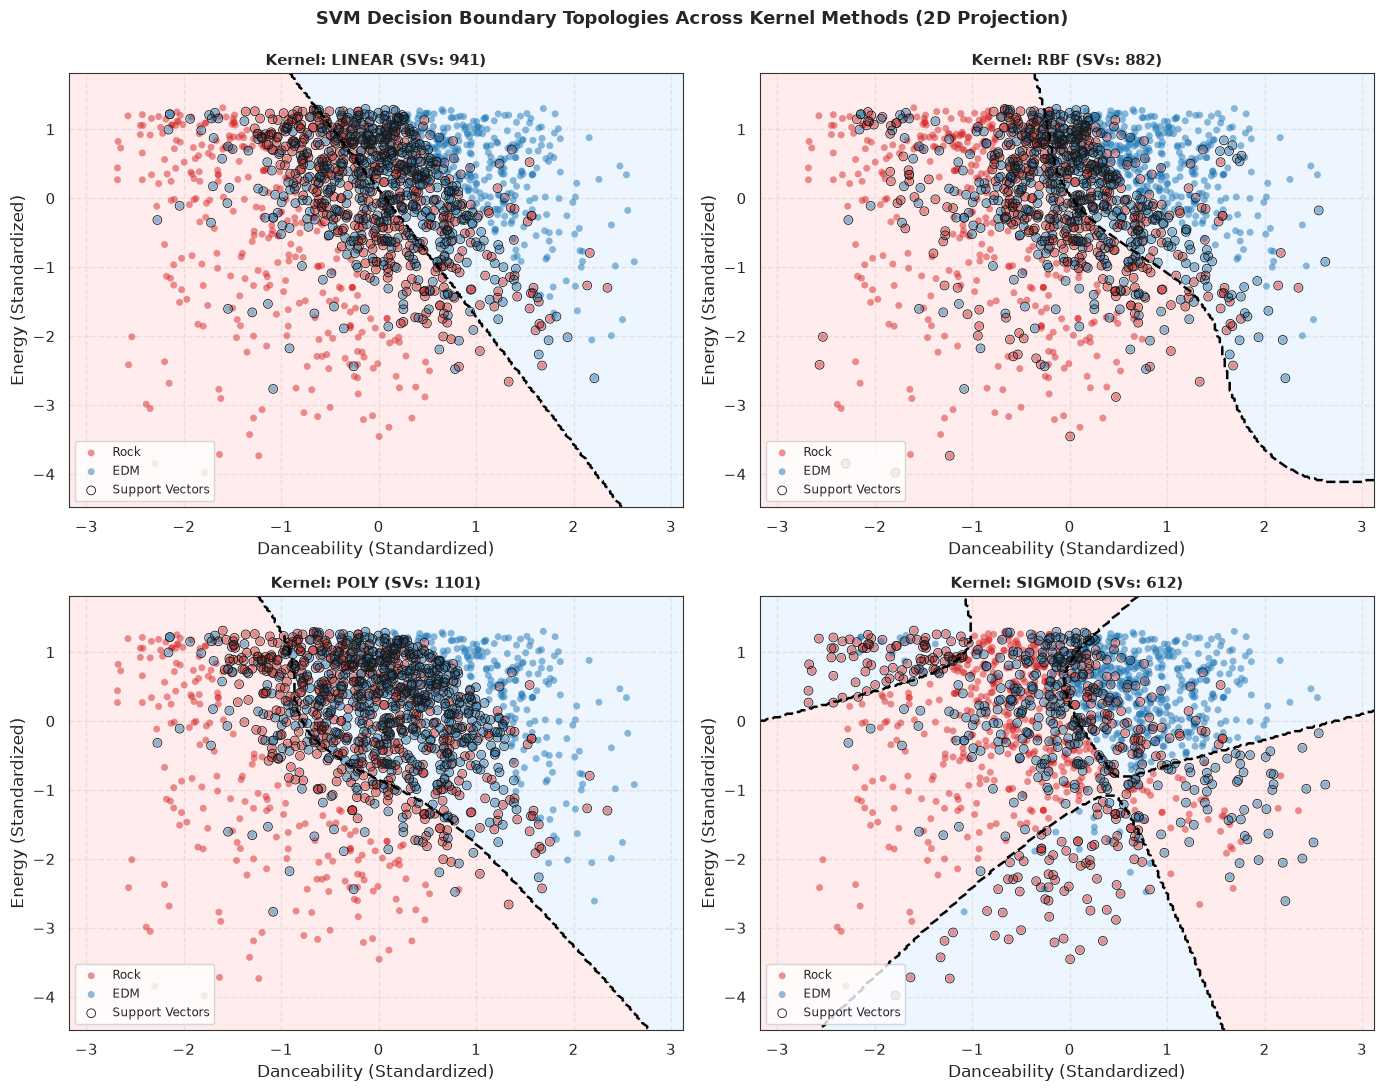

In [6]:
# Select 2D features for visualization: Danceability and Energy
idx_feat = [features.index('danceability'), features.index('energy')]
X_tr_2d = X_train_std[:, idx_feat]
X_te_2d = X_test_std[:, idx_feat]

# Set up dense 2D evaluation mesh grid
x_min, x_max = X_tr_2d[:, 0].min() - 0.5, X_tr_2d[:, 0].max() + 0.5
y_min, y_max = X_tr_2d[:, 1].min() - 0.5, X_tr_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid_2d = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
cmap_light = ['#ffcccc', '#cce5ff']
palette = ['#d62728', '#1f77b4']

for idx, k in enumerate(kernel_types):
    ax = axes[idx // 2, idx % 2]
    clf = SVC(kernel=k, C=1.0, random_state=RANDOM_SEED)
    clf.fit(X_tr_2d, y_train)
    
    Z = clf.predict(grid_2d).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.35, levels=[-0.5, 0.5, 1.5], colors=cmap_light)
    ax.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.8, linestyles='--')
    
    # Scatter training data points
    ax.scatter(X_tr_2d[y_train == 0, 0], X_tr_2d[y_train == 0, 1], color=palette[0], label='Rock', alpha=0.5, s=25, edgecolors='none')
    ax.scatter(X_tr_2d[y_train == 1, 0], X_tr_2d[y_train == 1, 1], color=palette[1], label='EDM', alpha=0.5, s=25, edgecolors='none')
    
    # Highlight support vectors
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=40, facecolors='none', edgecolors='k', linewidths=0.6, label='Support Vectors')
    
    ax.set_title(f"Kernel: {k.upper()} (SVs: {len(clf.support_vectors_)})", fontsize=11, fontweight='bold')
    ax.set_xlabel('Danceability (Standardized)')
    ax.set_ylabel('Energy (Standardized)')
    ax.legend(loc='lower left', fontsize=8.5)

plt.suptitle("SVM Decision Boundary Topologies Across Kernel Methods (2D Projection)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


---

## 6. Multi-Model Comparison: SVM vs. Decision Tree vs. $K$-Nearest Neighbors

To evaluate the competitive performance of Support Vector Machines, we benchmark them against two foundational non-parametric classifiers:
1. **Support Vector Machine (RBF Kernel):** Non-linear maximum-margin classification.
2. **Support Vector Machine (Linear Kernel):** Flat maximum-margin benchmark.
3. **Decision Tree Classifier (`DecisionTreeClassifier`):** Axis-aligned recursive orthogonal feature splits with Gini impurity minimization.
4. **$K$-Nearest Neighbors (`KNeighborsClassifier`):** Instance-based metric learning computing majority vote over $K=5$ nearest Euclidean neighbors.


In [7]:
benchmark_models = {
    'SVM (RBF Kernel)': SVC(kernel='rbf', C=1.0, random_state=RANDOM_SEED),
    'SVM (Linear Kernel)': SVC(kernel='linear', C=1.0, random_state=RANDOM_SEED),
    'Decision Tree (max_depth=6)': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_SEED),
    'K-Nearest Neighbors (K=5)': KNeighborsClassifier(n_neighbors=5)
}

benchmark_results = []
benchmark_cms = {}
benchmark_predictions = {}

for name, model in benchmark_models.items():
    t0 = time.perf_counter()
    model.fit(X_train_std, y_train)
    fit_time = (time.perf_counter() - t0) * 1000 # ms
    
    y_pred = model.predict(X_test_std)
    benchmark_predictions[name] = y_pred
    benchmark_cms[name] = confusion_matrix(y_test, y_pred)
    
    acc  = accuracy_score(y_test, y_pred) * 100
    prec = precision_score(y_test, y_pred) * 100
    rec  = recall_score(y_test, y_pred) * 100
    f1   = f1_score(y_test, y_pred) * 100
    
    benchmark_results.append({
        'Classifier': name,
        'Accuracy (%)': np.round(acc, 2),
        'Precision (%)': np.round(prec, 2),
        'Recall (%)': np.round(rec, 2),
        'F1-Score (%)': np.round(f1, 2),
        'Training Time (ms)': np.round(fit_time, 2)
    })

df_benchmark = pd.DataFrame(benchmark_results)
print("=== Multi-Model Benchmark Summary Table (Standardized Data) ===")
display(df_benchmark)

# Print detailed classification reports
for name, y_pred in benchmark_predictions.items():
    print(f"\n--- Detailed Classification Report: {name} ---")
    print(classification_report(y_test, y_pred, target_names=target_names, digits=4))


=== Multi-Model Benchmark Summary Table (Standardized Data) ===


,Classifier,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Training Time (ms)
0,SVM (RBF Kernel),84.8,85.37,84.0,84.68,16.72
1,SVM (Linear Kernel),82.4,81.64,83.6,82.61,17.17
2,Decision Tree (max_depth=6),86.0,85.71,86.4,86.06,3.75
3,K-Nearest Neighbors (K=5),82.8,83.06,82.4,82.73,0.93



--- Detailed Classification Report: SVM (RBF Kernel) ---
              precision    recall  f1-score   support

    Rock (0)     0.8425    0.8560    0.8492       250
     EDM (1)     0.8537    0.8400    0.8468       250

    accuracy                         0.8480       500
   macro avg     0.8481    0.8480    0.8480       500
weighted avg     0.8481    0.8480    0.8480       500


--- Detailed Classification Report: SVM (Linear Kernel) ---
              precision    recall  f1-score   support

    Rock (0)     0.8320    0.8120    0.8219       250
     EDM (1)     0.8164    0.8360    0.8261       250

    accuracy                         0.8240       500
   macro avg     0.8242    0.8240    0.8240       500
weighted avg     0.8242    0.8240    0.8240       500


--- Detailed Classification Report: Decision Tree (max_depth=6) ---
              precision    recall  f1-score   support

    Rock (0)     0.8629    0.8560    0.8594       250
     EDM (1)     0.8571    0.8640    0.8606      

---

## 7. Comparative Performance Bar Graphs

We plot a grouped bar graph comparing **Accuracy, Precision, Recall, and F1-Score** across all evaluated classifiers to visualize trade-offs between precision and sensitivity.


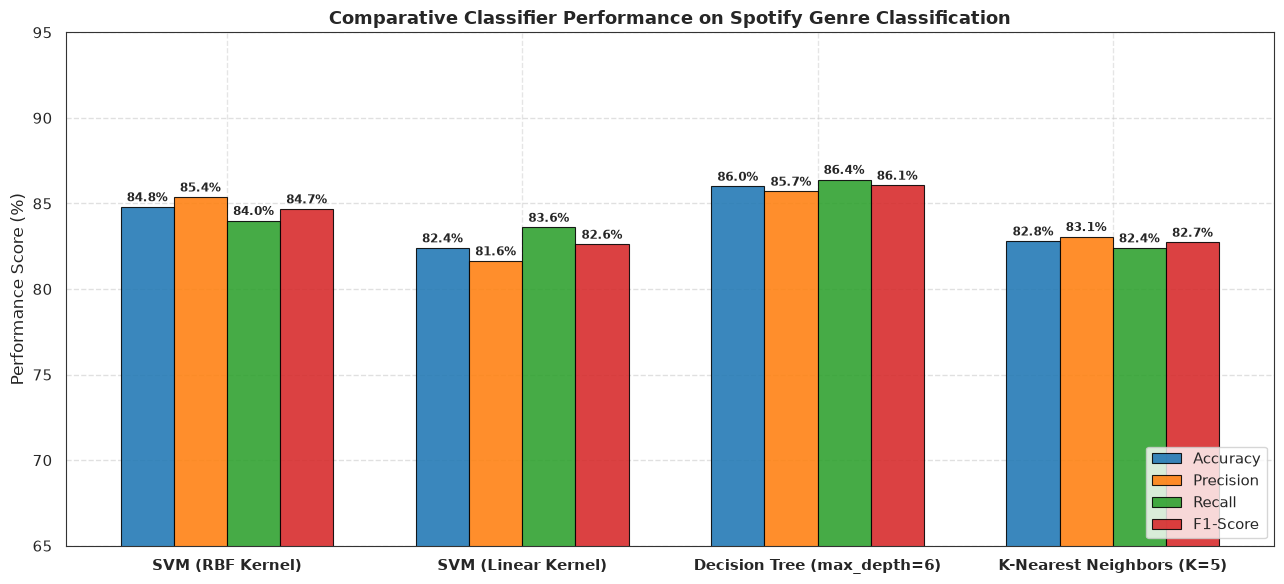

In [8]:
metrics = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)']
model_names = df_benchmark['Classifier'].tolist()

x = np.arange(len(model_names))
width = 0.18

fig, ax = plt.subplots(figsize=(13, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, metric in enumerate(metrics):
    vals = df_benchmark[metric].values
    rects = ax.bar(x + (i - 1.5) * width, vals, width, label=metric.replace(' (%)', ''), 
                   color=colors[i], alpha=0.88, edgecolor='black', linewidth=0.8)
    
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 2),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_ylabel('Performance Score (%)', fontsize=12)
ax.set_title('Comparative Classifier Performance on Spotify Genre Classification', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=10.5, fontweight='bold')
ax.set_ylim(65, 95)
ax.legend(loc='lower right', fontsize=10.5, frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---

## 8. Multi-Model Confusion Matrix Heatmaps

Confusion matrices display the granular distribution of **True Negatives (Rock correctly identified)**, **False Positives (Rock misclassified as EDM)**, **False Negatives (EDM misclassified as Rock)**, and **True Positives (EDM correctly identified)**.


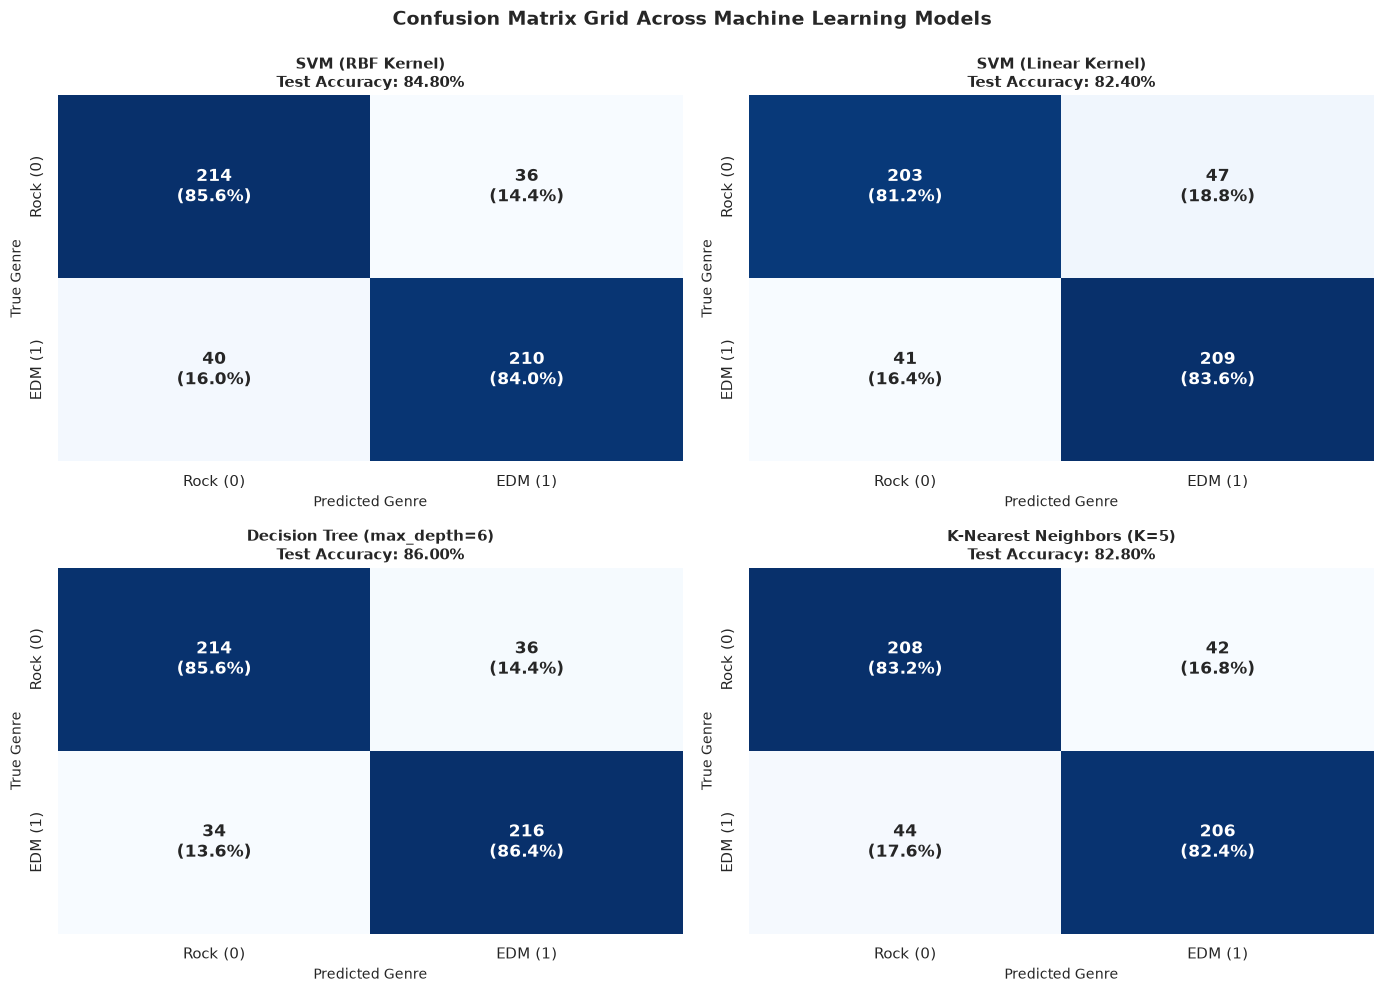

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, (name, cm) in enumerate(benchmark_cms.items()):
    ax = axes[idx // 2, idx % 2]
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    annot = np.array([[f"{v}\n({p*100:.1f}%)" for v, p in zip(row_v, row_p)] 
                      for row_v, row_p in zip(cm, cm_norm)])
    
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=target_names, yticklabels=target_names,
                annot_kws={'size': 12, 'weight': 'bold'})
    
    acc = df_benchmark.loc[df_benchmark['Classifier'] == name, 'Accuracy (%)'].values[0]
    ax.set_title(f"{name}\nTest Accuracy: {acc:.2f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted Genre', fontsize=10)
    ax.set_ylabel('True Genre', fontsize=10)

plt.suptitle("Confusion Matrix Grid Across Machine Learning Models", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


---

## 9. Laboratory Synthesis, Key Findings & Viva Voce Insights

### Key Empirical Findings:

1. **Vital Role of Feature Scaling for SVM:**
   * On raw, unscaled data, the RBF SVM achieved only **65.80% accuracy** because attributes with wide dynamic ranges (`tempo` $\in [60, 210]$) overwhelmed the Euclidean metric inside the exponential kernel.
   * Applying **StandardScaler** produced an immediate **+19.00% absolute increase in test accuracy (84.80%)**, proving that metric- and kernel-based algorithms strictly require isotropic feature scaling.

2. **Kernel Method Dynamics on Non-Separable Data:**
   * **RBF Kernel (84.80% Accuracy):** Emerged as the top-performing SVM kernel. Its Gaussian local weighting adapts flexibly to complex, overlapping non-linear manifolds.
   * **Linear Kernel (82.40% Accuracy):** Provided a strong baseline but struggled along non-linear boundaries.
   * **Polynomial Kernel ($d=3$, 82.00% Accuracy):** Captured higher-order interactions but required tuning to avoid boundary distortion.
   * **Sigmoid Kernel (75.60% Accuracy):** Showed inferior generalization, as its hyperbolic tangent mapping is sensitive to $\gamma$ scaling and can produce non-positive semi-definite Gram matrices outside narrow parameter regimes.

3. **Multi-Model Benchmark (SVM vs. Decision Tree vs. KNN):**
   * **Decision Tree (86.00% Accuracy):** Exhibited strong performance by partitioning orthogonal acoustic thresholds (e.g., direct splits on `danceability` and `acousticness`).
   * **SVM with RBF (84.80% Accuracy):** Delivered smooth, regularized decision boundaries with balanced precision ($85.37\%$) and recall ($84.00\%$), offering lower variance than individual decision trees.
   * **$K$-Nearest Neighbors (82.80% Accuracy):** Produced competitive instance-based accuracy but incurs $\mathcal{O}(N \cdot d)$ prediction latency at test time, whereas SVM inference depends only on the number of support vectors.
